# Baseline
Este avance consiste en construir un modelo de referencia que permita evaluar la viabilidad del problema. Si el baseline tiene un rendimiento similar al azar, podría indicar que el problema es intrínsecamente difícil o que los datos no contienen suficiente información para predecir el objetivo. De lo contrario, el baseline podría como una solución mínima aceptable cuando se trabaja en escenarios donde incluso un modelo simple puede proporcionar valor.

Un baseline facilita también la gestión de expectativas, tanto dentro del equipo como con los stakeholders, pues proporciona una comprensión inicial de lo que se puede lograr con métodos simples antes de invertir tiempo y recursos en enfoques más complejos.

Las siguientes son algunas de las preguntas que deberán abordar durante esta fase:

¿Qué algoritmo se puede utilizar como baseline para predecir las variables objetivo? 
¿Se puede determinar la importancia de las características para el modelo generado? Recuerden que incluir características irrelevantes puede afectar negativamente el rendimiento del modelo y aumentar la complejidad sin beneficios sustanciales.
¿El modelo está sub/sobreajustando los datos de entrenamiento?
¿Cuál es la métrica adecuada para este problema de negocio? 
¿Cuál debería ser el desempeño mínimo a obtener?

## Algoritmo
Tomando como baseline "ingenuo" se opta por hacer una discriminación por promedio.

In [31]:
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import GroupShuffleSplit

# Se asume una fila por caja, con columnas:
# imagen, x, y, w, h, image_width, image_height

df = pd.read_csv("../DataCapture/anotaciones_baseline.csv")

# Centro y límites de cada caja, expresados entre 0 y 1.
df["cx_norm"] = (df["x"] + df["w"] / 2) / df["image_width"]
df["cy_norm"] = (df["y"] + df["h"] / 2) / df["image_height"]
df["x1_norm"] = df["x"] / df["image_width"]
df["y1_norm"] = df["y"] / df["image_height"]
df["x2_norm"] = (df["x"] + df["w"]) / df["image_width"]
df["y2_norm"] = (df["y"] + df["h"]) / df["image_height"]

# Mantiene todas las cajas de cada imagen en el mismo grupo.
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)
train_idx, test_idx = next(
    splitter.split(df, groups=df["imagen"])
)

train = df.iloc[train_idx].copy()
test = df.iloc[test_idx].copy()

# Promedio de centros por imagen y luego entre imágenes:
# cada imagen pesa igual, aunque tenga distinto número de cajas.
centers_by_image = train.groupby("imagen")[["cx_norm", "cy_norm"]].mean()
pred_x, pred_y = centers_by_image.mean().to_numpy()

# Evalúa si el punto promedio cae dentro de alguna caja real
# de cada imagen de prueba.
results = []

for image_name, boxes in test.groupby("imagen"):
    hit = (
        (boxes["x1_norm"] <= pred_x) &
        (pred_x <= boxes["x2_norm"]) &
        (boxes["y1_norm"] <= pred_y) &
        (pred_y <= boxes["y2_norm"])
    ).any()

    results.append({"imagen": image_name, "hit": hit})

results = __import__("pandas").DataFrame(results)
hit_rate = results["hit"].mean()

print(f"Punto promedio: ({pred_x:.3f}, {pred_y:.3f})")
print(f"Imágenes de prueba con alguna caja: {len(results)}")
print(f"Tasa de acierto por imagen: {hit_rate:.1%}")


Punto promedio: (0.499, 0.519)
Imágenes de prueba con alguna caja: 9
Tasa de acierto por imagen: 0.0%


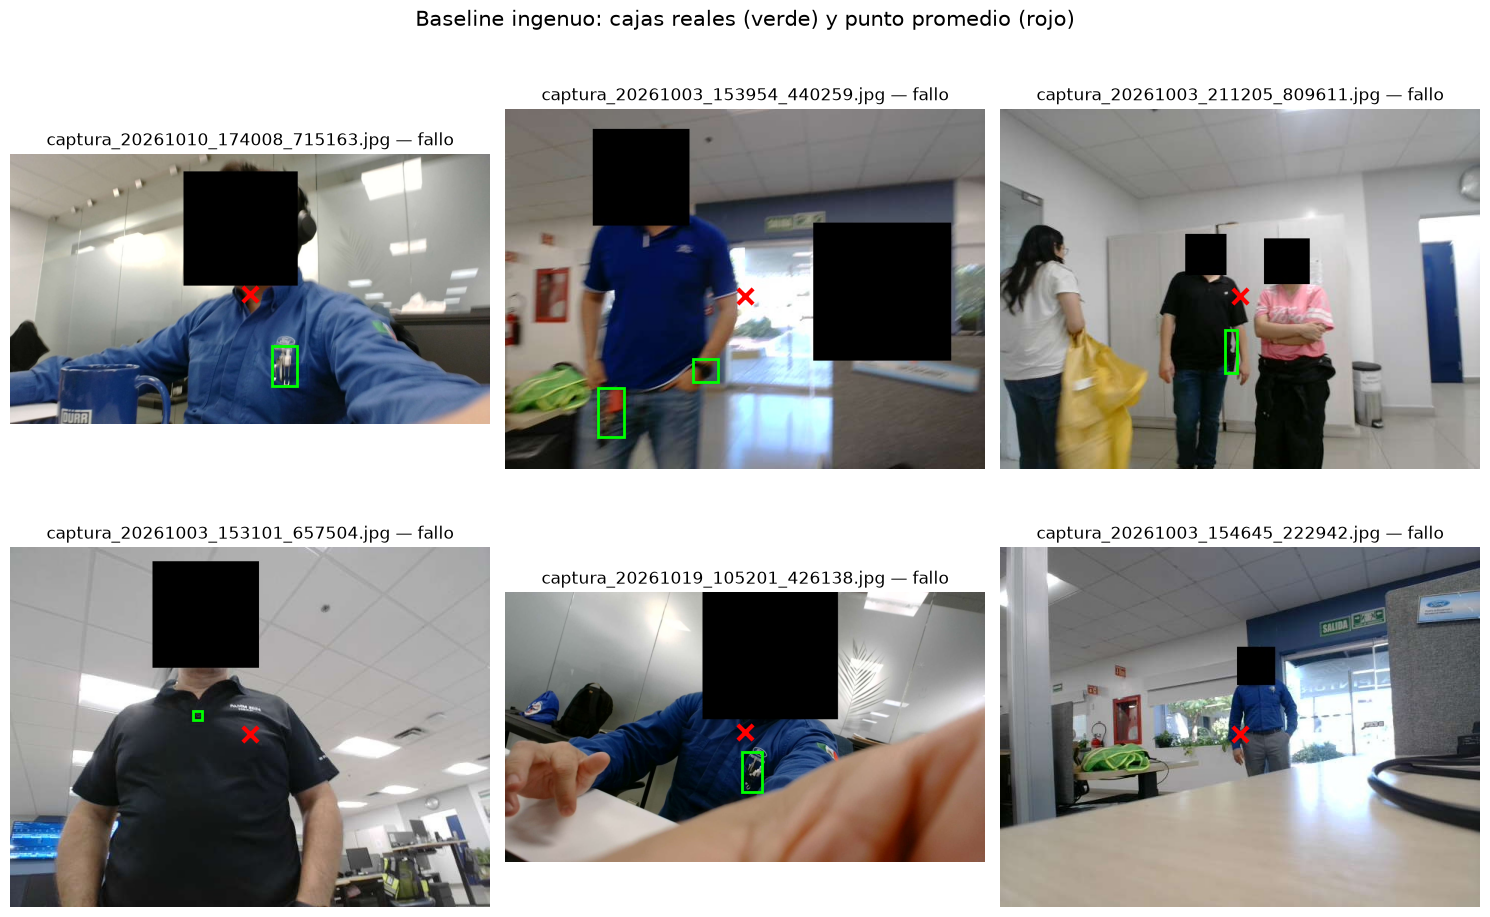

In [32]:
from pathlib import Path
import math

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Rectangle


IMAGE_DIR = Path("../DataCapture/raw")
N_IMAGES = 6

# Una imagen puede tener varias cajas; seleccionamos imágenes únicas.
image_names = test["imagen"].drop_duplicates()
sample_names = image_names.sample(
    n=min(N_IMAGES, len(image_names)),
    random_state=42
).tolist()

ncols = 3
nrows = math.ceil(len(sample_names) / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 5 * nrows))
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

for ax, image_name in zip(axes, sample_names):
    image_path = IMAGE_DIR / Path(image_name).name
    image_bgr = cv2.imread(str(image_path))

    if image_bgr is None:
        ax.set_title(f"No se pudo leer: {image_name}")
        ax.axis("off")
        continue

    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    height, width = image.shape[:2]

    # Dibuja todas las cajas reales de esa imagen.
    boxes = test[test["imagen"] == image_name]
    for row in boxes.itertuples():
        ax.add_patch(Rectangle(
            (row.x, row.y),
            row.w,
            row.h,
            fill=False,
            edgecolor="lime",
            linewidth=2
        ))

    # Convierte el punto promedio normalizado a píxeles.
    point_x = pred_x * width
    point_y = pred_y * height

    # Comprueba si el punto cae dentro de alguna caja real.
    hit = (
        (boxes["x1_norm"] <= pred_x) &
        (pred_x <= boxes["x2_norm"]) &
        (boxes["y1_norm"] <= pred_y) &
        (pred_y <= boxes["y2_norm"])
    ).any()

    ax.scatter(point_x, point_y, marker="x", s=120, c="red", linewidths=3)
    ax.imshow(image)
    ax.set_title(f"{Path(image_name).name} — {'acierto' if hit else 'fallo'}")
    ax.axis("off")

# Oculta los espacios que no se usaron.
for ax in axes[len(sample_names):]:
    ax.axis("off")

fig.suptitle(
    "Baseline ingenuo: cajas reales (verde) y punto promedio (rojo)",
    fontsize=15
)
plt.tight_layout()
plt.show()


## Matriz de confusión de modelo ingeuo

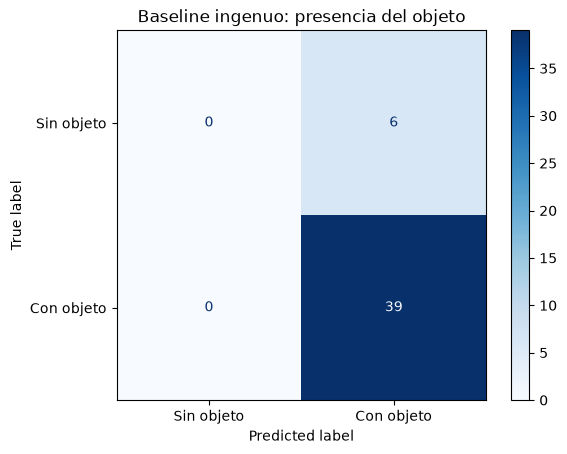

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

# test_manifest: una fila por imagen de prueba, incluyendo negativas confirmadas.
test_manifest=df.drop_duplicates(subset=["imagen"])[["imagen", "cx_norm", "cy_norm"]].copy()
test_manifest["tiene_objeto"] = (test_manifest["cx_norm"].isna() == False)*1
# Columnas requeridas: tiene_objeto (0/1)
#eval_df = test_manifest.dropna(subset=["tiene_objeto"]).copy()
eval_df= test_manifest["tiene_objeto"].astype(int)

#y_true = eval_df["tiene_objeto"].astype(int)
y_true=eval_df.to_numpy()

# El baseline siempre emite un punto; interpretado como
# "predice que hay un objeto", predice positivo en todas las imágenes.
y_pred = np.ones(len(eval_df), dtype=int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sin objeto", "Con objeto"]
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Baseline ingenuo: presencia del objeto")
plt.show()


Como mecanismo de arranque el discriminador "ingenuo" predice que todas las imagenes poseen anomalía por lo que su matriz de confusión posee problemas para detectar cumplimiento de estandar.   
Un segundo enfoque es clasificar cada una de las detecciones en el dataset y ver si el promedio atina o no al objeto en cuestión.

In [34]:
import pandas as pd

# test debe conservar x1_norm, y1_norm, x2_norm, y2_norm.
# pred_x y pred_y son el punto promedio calculado usando solo entrenamiento.
test = test.copy()

# Resultado por caja: ¿el punto promedio cae dentro de esta caja?
test["punto_dentro_caja"] = (
    (test["x1_norm"] <= pred_x) &
    (pred_x <= test["x2_norm"]) &
    (test["y1_norm"] <= pred_y) &
    (pred_y <= test["y2_norm"])
)

# Resumen por imagen: cuenta como acierto si cae dentro de al menos una caja.
por_imagen = (
    test.groupby("imagen")
    .agg(
        acierto=("punto_dentro_caja", "any"),
        numero_cajas=("punto_dentro_caja", "size")
    )
    .reset_index()
)

tasa_acierto = por_imagen["acierto"].mean()

print(f"Imágenes evaluadas: {len(por_imagen)}")
print(f"Imágenes donde el punto cae dentro de alguna caja: "
      f"{por_imagen['acierto'].sum()}")
print(f"Tasa de acierto espacial por imagen: {tasa_acierto:.1%}")

por_imagen.head()


Imágenes evaluadas: 9
Imágenes donde el punto cae dentro de alguna caja: 0
Tasa de acierto espacial por imagen: 0.0%


,imagen,acierto,numero_cajas
0,captura_20261003_153101_657504.jpg,False,1
1,captura_20261003_153954_440259.jpg,False,2
2,captura_20261003_154645_222942.jpg,False,1
3,captura_20261003_161339_046776.jpg,False,1
4,captura_20261003_161925_712237.jpg,False,1


## Características importantes
Puesto que los recortes son coordenadas dimensionales no relacionadas al objeto en sí es posible descartar las variables x, y, w y h como inputs al modelo; sin embargo el primer enfoque del promedio para una detección ingenua nos arroja en varios sets de prueba un 22% de tasa de aciertos en los positivos y es incapaz de detectar los negativos.  Para este caso un negativo es el cumplimiento de estandar.  
### Modelo Faster R-CNN  
Se construye un primer modelo para detectar objetos.  
Existen 2 enfoques posibles para la salida del modelo:
* Devolver una lista de detecciones  
* Devolver un heatmap 2D con picos en donde haya detecciones.  
El modelo Faster R-CNN ya posee la capacidad de regresar una lista de coordenadas x,y y longitudes de detección de w y h.
El segundo enfoque se guardaría como posible modelo alternativo para explorarse al futuro.

In [35]:
revisado = test_manifest.drop_duplicates(subset=["imagen"])[["imagen", "tiene_objeto"]].to_csv("../DataCapture/revisado.csv", index=False)

In [36]:
from pathlib import Path

import pandas as pd
import torch
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import functional as TF
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

import copy
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader


# ------------------------------------------------------------------
# 1. Configuración: ingresa las ubicaciones al ejecutar la celda
# ------------------------------------------------------------------
IMAGE_DIR= Path("../DataCapture/raw")
ANNOTATIONS_CSV= Path("../DataCapture/anotaciones.csv")
REVIEWED_CSV= Path("../DataCapture/revisado.csv")

#IMAGE_DIR = Path(input("Carpeta de imágenes originales completas: ").strip())
#ANNOTATIONS_CSV = Path(input("CSV con imagen, x, y, w, h: ").strip())
#REVIEWED_CSV = Path(input("CSV con una fila por imagen revisada: ").strip())

# Si tus columnas tienen otros nombres, cámbialos aquí.
IMAGE_COL = "imagen"
X_COL, Y_COL, W_COL, H_COL = "x", "y", "w", "h"

BATCH_SIZE = 2
EPOCHS = 10
RANDOM_STATE = 42


# ------------------------------------------------------------------
# 2. Cargar y validar anotaciones e imágenes revisadas
# ------------------------------------------------------------------

annotations = pd.read_csv(ANNOTATIONS_CSV)
reviewed = pd.read_csv(REVIEWED_CSV)

required_ann_cols = {IMAGE_COL, X_COL, Y_COL, W_COL, H_COL}
missing = required_ann_cols - set(annotations.columns)
if missing:
    raise ValueError(f"Faltan columnas en el CSV de anotaciones: {missing}")

if IMAGE_COL not in reviewed.columns:
    raise ValueError(f"El CSV de imágenes revisadas debe incluir '{IMAGE_COL}'.")

# En este ejemplo se espera que el CSV use nombres de archivo.
annotations[IMAGE_COL] = annotations[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)
reviewed[IMAGE_COL] = reviewed[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)

# Una fila por imagen en el manifiesto de imágenes revisadas.
reviewed = reviewed.drop_duplicates(subset=[IMAGE_COL]).reset_index(drop=True)

# Solo se admiten anotaciones de imágenes que estén en el manifiesto revisado.
unknown_images = set(annotations[IMAGE_COL]) - set(reviewed[IMAGE_COL])
if unknown_images:
    raise ValueError(
        "Hay anotaciones de imágenes que no aparecen en el CSV de revisadas. "
        f"Ejemplos: {list(unknown_images)[:5]}"
    )

# ------------------------------------------------------------------
# 3. Separación por imagen o por sesión para evitar fuga de datos
# ------------------------------------------------------------------

# Si el manifiesto tiene una columna 'session', las imágenes de una misma
# sesión permanecen juntas. Si no, se agrupa por imagen.
if "session" in reviewed.columns:
    groups = reviewed["session"].fillna(reviewed[IMAGE_COL]).astype(str)
else:
    groups = reviewed[IMAGE_COL].astype(str)

# 70 % entrenamiento, 15 % validación y 15 % prueba, aproximadamente.
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=RANDOM_STATE
)
trainval_idx, test_idx = next(
    split1.split(reviewed, groups=groups)
)

trainval = reviewed.iloc[trainval_idx].reset_index(drop=True)
test_df = reviewed.iloc[test_idx].reset_index(drop=True)

if "session" in trainval.columns:
    trainval_groups = (
        trainval["session"].fillna(trainval[IMAGE_COL]).astype(str)
    )
else:
    trainval_groups = trainval[IMAGE_COL].astype(str)

# 15 % del total equivale a ~17.6 % del bloque train+validation.
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=RANDOM_STATE
)
train_idx, val_idx = next(
    split2.split(trainval, groups=trainval_groups)
)

train_df = trainval.iloc[train_idx].reset_index(drop=True)
val_df = trainval.iloc[val_idx].reset_index(drop=True)

print(
    f"Imágenes: entrenamiento={len(train_df)}, "
    f"validación={len(val_df)}, prueba={len(test_df)}"
)


# ------------------------------------------------------------------
# 4. Dataset: cada imagen devuelve píxeles y cajas reales
# ------------------------------------------------------------------
class AccessoryDataset(Dataset):
    def __init__(self, manifest, annotations, image_dir):
        self.image_names = manifest[IMAGE_COL].tolist()
        self.image_dir = image_dir
        self.annotations_by_image = {
            name: group
            for name, group in annotations.groupby(IMAGE_COL)
        }

    def __len__(self):
        return len(self.image_names)

    def __getitem__(self, index):
        image_name = self.image_names[index]
        image_path = self.image_dir / image_name

        image = Image.open(image_path).convert("RGB")
        image_width, image_height = image.size

        rows = self.annotations_by_image.get(image_name)

        boxes = []
        if rows is not None:
            for row in rows.itertuples(index=False):
                x = float(getattr(row, X_COL))
                y = float(getattr(row, Y_COL))
                w = float(getattr(row, W_COL))
                h = float(getattr(row, H_COL))

                # CSV [x, y, w, h] -> Faster R-CNN [x1, y1, x2, y2].
                x1 = max(0.0, x)
                y1 = max(0.0, y)
                x2 = min(float(image_width), x + w)
                y2 = min(float(image_height), y + h)

                if x2 <= x1 or y2 <= y1:
                    raise ValueError(
                        f"Caja inválida en {image_name}: "
                        f"{x}, {y}, {w}, {h}"
                    )

                boxes.append([x1, y1, x2, y2])

        # Una imagen revisada sin objetos tiene una matriz de cajas vacía.
        boxes = torch.as_tensor(boxes, dtype=torch.float32).reshape(-1, 4)

        # 0 se reserva para fondo; 1 es la clase 'accesorio'.
        labels = torch.ones((len(boxes),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "image_id": torch.tensor([index], dtype=torch.int64),
        }

        # Convierte la imagen RGB a tensor float en [0, 1].
        image_tensor = TF.to_tensor(image)

        return image_tensor, target


def collate_fn(batch):
    # El detector admite imágenes de diferentes tamaños.
    return tuple(zip(*batch))


train_dataset = AccessoryDataset(train_df, annotations, IMAGE_DIR)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    collate_fn=collate_fn
)


# ------------------------------------------------------------------
# 5. Crear Faster R-CNN preentrenado y reemplazar su clasificador
# ------------------------------------------------------------------

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", device)

# Los pesos preentrenados pueden descargarse la primera vez.
model = fasterrcnn_resnet50_fpn(weights="DEFAULT")

# Dos clases contando el fondo: fondo=0, accesorio=1.
num_classes = 2
in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(
    in_features,
    num_classes
)

model.to(device)


# ------------------------------------------------------------------
# 6. Entrenamiento
# ------------------------------------------------------------------
train_losses = []
val_losses = []
MODELS_DIR = Path("../Models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)
# DataLoader de validación
val_dataset = AccessoryDataset(val_df, annotations, IMAGE_DIR)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_fn
)

best_val_loss = float("inf")
best_model_state = None

EPOCH3_PATH = MODELS_DIR / "best_fit"
BEST_PATH = MODELS_DIR / "fasterrcnn_accesorio_best_val.pth"

optimizer = torch.optim.SGD(
    [p for p in model.parameters() if p.requires_grad],
    lr=0.005,
    momentum=0.9,
    weight_decay=0.0005
)

scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

for epoch in range(EPOCHS):
    # -------------------------
    # Entrenamiento
    # -------------------------
    model.train()
    train_total = 0.0
    train_batches = 0

    for images, targets in train_loader:
        images = [image.to(device) for image in images]
        targets = [
            {key: value.to(device) for key, value in target.items()}
            for target in targets
        ]

        loss_dict = model(images, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_total += loss.detach().item()
        train_batches += 1

    mean_train_loss = train_total / max(train_batches, 1)
    train_losses.append(mean_train_loss)

    # -------------------------
    # Validación: calcular pérdidas, sin actualizar pesos
    # -------------------------
    # Torchvision devuelve las pérdidas cuando el detector está en modo train.
    # No se calculan gradientes ni se actualiza el optimizador.
    model.train()
    val_total = 0.0
    val_batches = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = [image.to(device) for image in images]
            targets = [
                {key: value.to(device) for key, value in target.items()}
                for target in targets
            ]

            val_loss_dict = model(images, targets)
            val_loss = sum(val_loss_dict.values())

            val_total += val_loss.item()
            val_batches += 1

    mean_val_loss = val_total / max(val_batches, 1)
    val_losses.append(mean_val_loss)

    epoch_num = epoch + 1  # Python cuenta desde 0; la época visible empieza en 1.

    if epoch_num == 3:
        torch.save(
            {
                "epoch": epoch_num,
                "model_state_dict": model.state_dict(),
                "train_loss": mean_train_loss,
                "val_loss": mean_val_loss,
            },
            EPOCH3_PATH
        )
        print(f"Checkpoint de época 3 guardado: {EPOCH3_PATH.name}")

    scheduler.step()

    print(
        f"Época {epoch + 1:02d}/{EPOCHS} | "
        f"train loss: {mean_train_loss:.4f} | "
        f"val loss: {mean_val_loss:.4f}"
    )

    # Conserva el modelo de la época con menor pérdida de validación.
    if mean_val_loss < best_val_loss:
        best_val_loss = mean_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

# Restaurar el mejor punto según validación, no necesariamente la última época.
if best_model_state is not None:
    model.load_state_dict(best_model_state)

# ------------------------------------------------------------------
# 7. Guardar el modelo entrenado
# ------------------------------------------------------------------

#checkpoint_name = input(
#    "Nombre del archivo para guardar el modelo: "
#).strip()
checkpoint_name="../corrida.pth"

if not checkpoint_name:
    checkpoint_name = "fasterrcnn_accesorio.pth"

torch.save(model.state_dict(), checkpoint_name)
print("Modelo guardado.")


# ------------------------------------------------------------------
# 8. Probar una imagen y convertir las cajas a [x, y, w, h]
# ------------------------------------------------------------------

model.eval()

test_name = test_df.iloc[0][IMAGE_COL]
test_image = Image.open(IMAGE_DIR / test_name).convert("RGB")
test_tensor = TF.to_tensor(test_image).to(device)

with torch.no_grad():
    prediction = model([test_tensor])[0]

# Umbral inicial de confianza; después ajústalo usando validación.
SCORE_THRESHOLD = 0.50
keep = prediction["scores"] >= SCORE_THRESHOLD

pred_boxes = prediction["boxes"][keep].cpu()
pred_scores = prediction["scores"][keep].cpu()
pred_labels = prediction["labels"][keep].cpu()

detections = []
for box, score, label in zip(pred_boxes, pred_scores, pred_labels):
    x1, y1, x2, y2 = box.tolist()

    detections.append({
        "clase": "accesorio",
        "x": x1,
        "y": y1,
        "w": x2 - x1,
        "h": y2 - y1,
        "confianza": float(score),
    })

detections_df = pd.DataFrame(detections)
print("Imagen:", test_name)
display(detections_df)

Imágenes: entrenamiento=31, validación=7, prueba=7
Dispositivo: cpu
Época 01/10 | train loss: 0.3925 | val loss: 0.2926
Época 02/10 | train loss: 0.2915 | val loss: 0.2432
Checkpoint de época 3 guardado: best_fit
Época 03/10 | train loss: 0.2789 | val loss: 0.2159
Época 04/10 | train loss: 0.2352 | val loss: 0.2791
Época 05/10 | train loss: 0.1858 | val loss: 0.2832
Época 06/10 | train loss: 0.1551 | val loss: 0.2795
Época 07/10 | train loss: 0.1331 | val loss: 0.2728
Época 08/10 | train loss: 0.1301 | val loss: 0.2795
Época 09/10 | train loss: 0.1163 | val loss: 0.2868
Época 10/10 | train loss: 0.1166 | val loss: 0.2986
Modelo guardado.
Imagen: captura_20261003_153101_657504.jpg


""


### Modelo de salida
El modelo de salida se guardó en carpeta "../Models/*".  Sin embargo por el peso de 160 MB se agregó a lista de "gitignore".

## Sub/sobre ajuste

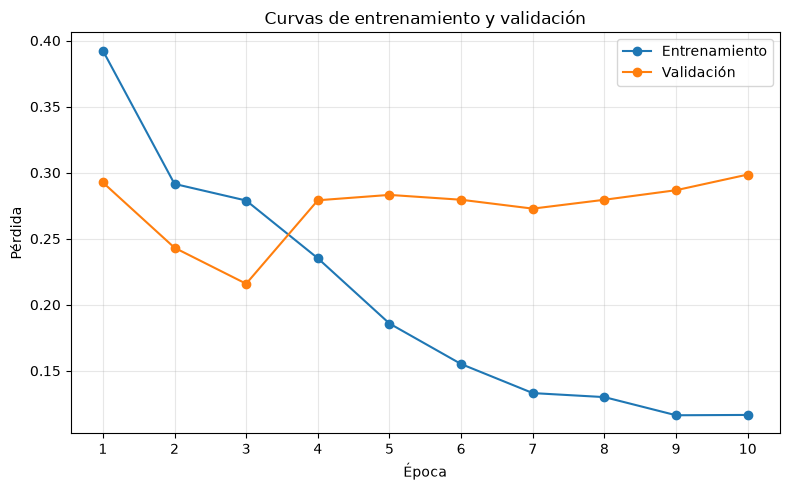

In [37]:
# -------------------------
# Gráfica
# -------------------------
epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, marker="o", label="Entrenamiento")
plt.plot(epochs, val_losses, marker="o", label="Validación")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Curvas de entrenamiento y validación")
plt.xticks(list(epochs))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

### Reflexiones
Las curvas muestran que el set de validación fue incapaz de mejorar su desempeño con las épocas, por lo que el algoritmo estuvo "memorizando" tras 3 épocas.  
El modelo se puede validar para revisar si mejora el sistema "baseline".

## Métrica
Seleccionando la métrica con el mejor set de validación.

In [38]:
import numpy as np
import torch

best_epoch = val_losses.index(min(val_losses)) + 1
best_epoch3=3

torch.save(
    {
        "epoch": best_epoch,
        "model_state_dict": best_model_state,
        "val_losses": val_losses,
        "train_losses": train_losses,
    },
    "../Models/min_val"
    #input("Nombre del checkpoint del mejor modelo: ").strip()
)

torch.save(
    {
        "epoch": best_epoch3,
        "model_state_dict": best_model_state,
        "val_losses": val_losses,
        "train_losses": train_losses,
    },
    "../Models/best_fit"
    #input("Nombre del checkpoint del mejor modelo: ").strip()
)

## Matriz de confusión

In [39]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


# Elige el umbral usando validación, no optimizándolo sobre prueba.
SCORE_THRESHOLD = 0.50

# Cargar el checkpoint seleccionado.
checkpoint_file="../Models/best_fit"
#checkpoint_file = input("Archivo del checkpoint del modelo: ").strip()

try:
    checkpoint = torch.load(
        checkpoint_file,
        map_location=device,
        weights_only=True
    )
except TypeError:
    # Compatibilidad con versiones antiguas de PyTorch.
    checkpoint = torch.load(checkpoint_file, map_location=device)

state = (
    checkpoint["model_state_dict"]
    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint
    else checkpoint
)

# Recrear la arquitectura de una clase más el fondo.
model_eval = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)
in_features = model_eval.roi_heads.box_predictor.cls_score.in_features
model_eval.roi_heads.box_predictor = FastRCNNPredictor(in_features, 2)

model_eval.load_state_dict(state)
model_eval.to(device)
model_eval.eval()

to_tensor = transforms.ToTensor()

# Normalizar los nombres para que coincidan entre manifiesto y CSV.
ann = annotations.copy()
ann[IMAGE_COL] = ann[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)

train_names = set(
    train_df[IMAGE_COL].astype(str).map(lambda name: Path(name).name)
)
test_names = (
    test_df[IMAGE_COL].astype(str).map(lambda name: Path(name).name).tolist()
)

ann_by_image = {
    name: group
    for name, group in ann.groupby(IMAGE_COL)
}


def get_image_boxes(image_name, width, height):
    """Devuelve cajas reales xyxy, limitadas al tamaño de la imagen."""
    rows = ann_by_image.get(image_name)
    boxes = []

    if rows is None:
        return boxes

    for row in rows.itertuples(index=False):
        x = float(getattr(row, "x"))
        y = float(getattr(row, "y"))
        w = float(getattr(row, "w"))
        h = float(getattr(row, "h"))

        x1 = max(0.0, x)
        y1 = max(0.0, y)
        x2 = min(float(width), x + w)
        y2 = min(float(height), y + h)

        if x2 > x1 and y2 > y1:
            boxes.append((x1, y1, x2, y2))

    return boxes


# Recalcular el punto promedio usando solo imágenes de entrenamiento.
# Cada imagen tiene el mismo peso, independientemente de cuántas cajas tenga.
centros_por_imagen = []

for image_name in sorted(train_names):
    image_path = IMAGE_DIR / image_name

    with Image.open(image_path) as image:
        width, height = image.size

    boxes = get_image_boxes(image_name, width, height)

    if boxes:
        centros = [
            (((x1 + x2) / 2) / width, ((y1 + y2) / 2) / height)
            for x1, y1, x2, y2 in boxes
        ]
        centros_por_imagen.append(np.mean(centros, axis=0))

if not centros_por_imagen:
    raise ValueError("No se encontraron cajas anotadas en entrenamiento.")

pred_x_norm, pred_y_norm = np.mean(centros_por_imagen, axis=0)


# Evaluar baseline y detector en las mismas imágenes de prueba.
rows = []

for image_name in test_names:
    image_path = IMAGE_DIR / image_name

    with Image.open(image_path) as pil_image:
        image = pil_image.convert("RGB")
        width, height = image.size
        image_tensor = to_tensor(image).to(device)

    gt_boxes = get_image_boxes(image_name, width, height)
    gt_positive = len(gt_boxes) > 0

    # Baseline: punto fijo en coordenadas normalizadas.
    baseline_x = pred_x_norm * width
    baseline_y = pred_y_norm * height

    baseline_hit = any(
        x1 <= baseline_x <= x2 and y1 <= baseline_y <= y2
        for x1, y1, x2, y2 in gt_boxes
    )

    # Detector: conserva predicciones por encima del umbral de confianza.
    with torch.no_grad():
        pred = model_eval([image_tensor])[0]

    keep = pred["scores"].cpu().numpy() >= SCORE_THRESHOLD
    pred_boxes = pred["boxes"].cpu().numpy()[keep]

    # Métrica comparable al baseline:
    # ¿el centro de alguna caja predicha cae dentro de una caja real?
    detector_center_hit = any(
        x1 <= (px1 + px2) / 2 <= x2
        and y1 <= (py1 + py2) / 2 <= y2
        for px1, py1, px2, py2 in pred_boxes
        for x1, y1, x2, y2 in gt_boxes
    )

    rows.append({
        "imagen": image_name,
        "tiene_objeto": gt_positive,
        "baseline_acierto": baseline_hit,
        "detector_acierto_centro": detector_center_hit,
        "detector_predice_objeto": len(pred_boxes) > 0,
        "num_detecciones": len(pred_boxes),
    })

results = pd.DataFrame(rows)

# Comparación de localización solo en imágenes positivas.
positive_results = results[results["tiene_objeto"]]

if len(positive_results) == 0:
    raise ValueError("El conjunto de prueba no tiene imágenes positivas.")

baseline_rate = positive_results["baseline_acierto"].mean()
detector_rate = positive_results["detector_acierto_centro"].mean()

print(f"Imágenes positivas evaluadas: {len(positive_results)}")
print(f"Baseline de punto promedio: {baseline_rate:.1%}")
print(f"Detector, centro dentro de caja real: {detector_rate:.1%}")
print(f"Diferencia: {(detector_rate - baseline_rate) * 100:+.1f} puntos porcentuales")


Imágenes positivas evaluadas: 7
Baseline de punto promedio: 14.3%
Detector, centro dentro de caja real: 57.1%
Diferencia: +42.9 puntos porcentuales


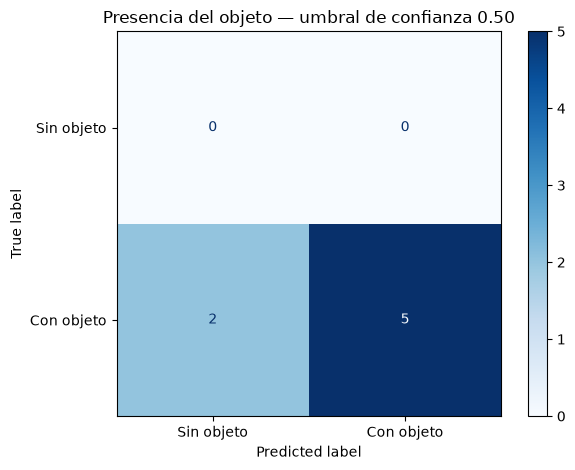

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(
    results["tiene_objeto"],
    results["detector_predice_objeto"],
    labels=[False, True]
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Sin objeto", "Con objeto"]
).plot(cmap="Blues", values_format="d")

plt.title(f"Presencia del objeto — umbral de confianza {SCORE_THRESHOLD:.2f}")
plt.tight_layout()
plt.show()


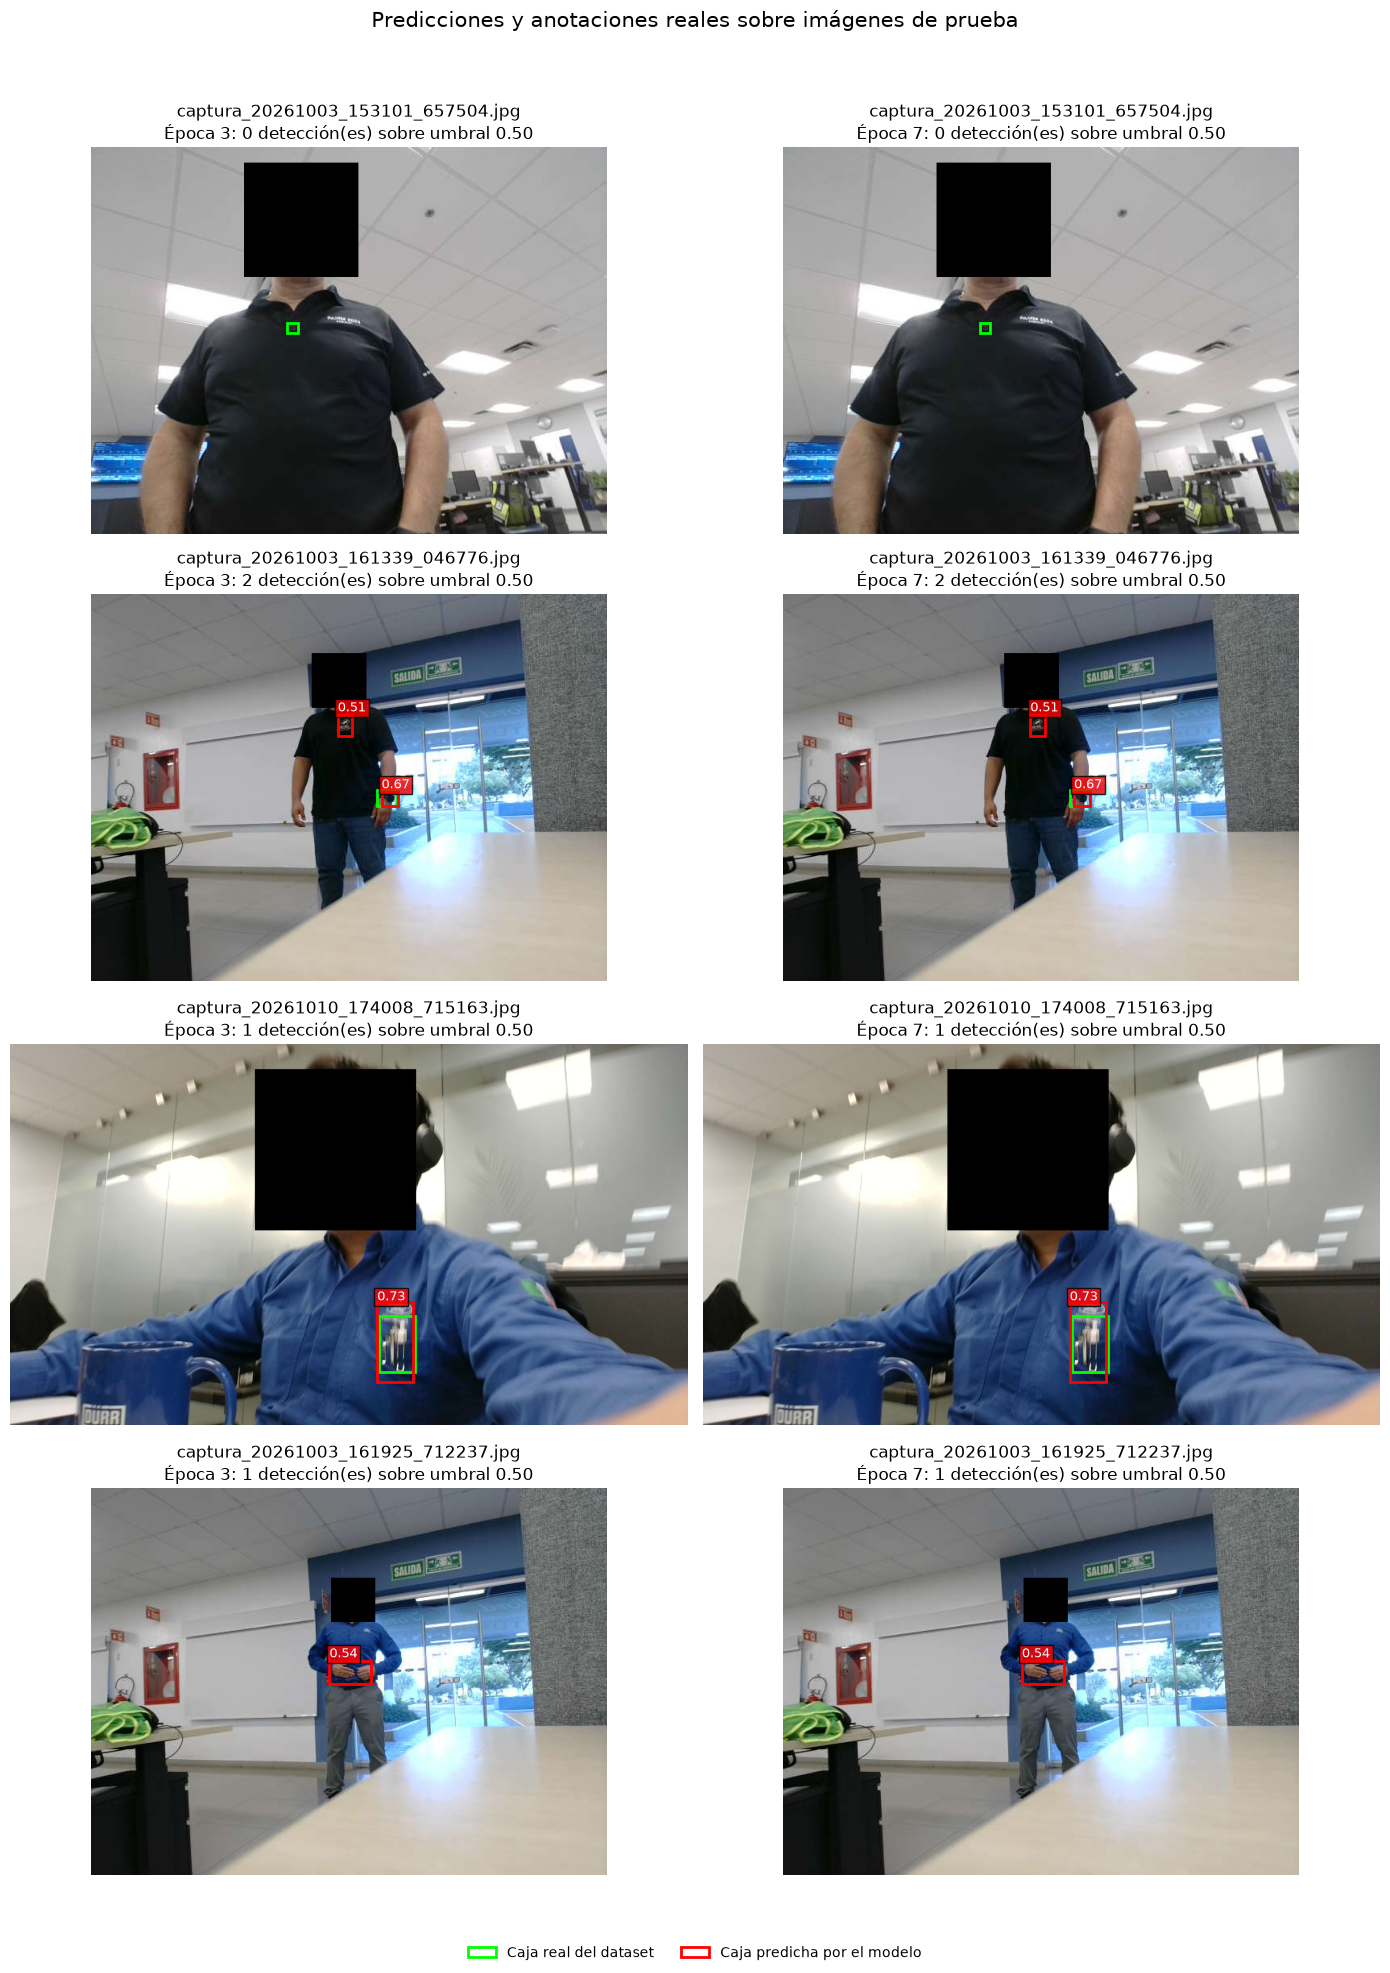

In [41]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from matplotlib.patches import Patch, Rectangle
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


# Ingresa los checkpoints disponibles.
# Si no tienes uno de ellos, deja su respuesta vacía.
checkpoint_paths = {
    #"Época 3": input("Checkpoint de época 3 (o Enter para omitir): ").strip(),
    #"Época 7": input("Checkpoint de época 7 (o Enter para omitir): ").strip(),
    "Época 3":"../Models/best_fit",
    "Época 7": "../Models/min_val",
}
checkpoint_paths = {
    name: path for name, path in checkpoint_paths.items() if path
}

if not checkpoint_paths:
    raise ValueError("Ingresa al menos un checkpoint disponible.")

# Usa el umbral que hayas seleccionado con el set de validación.
SCORE_THRESHOLD = 0.50
N_IMAGES = 4
RANDOM_STATE = 42

to_tensor = transforms.ToTensor()


def load_detector(checkpoint_path):
    """Reconstruye el detector y carga sus pesos guardados."""
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    except TypeError:
        # Compatibilidad con versiones anteriores de PyTorch.
        checkpoint = torch.load(checkpoint_path, map_location=device)

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        # También admite un state_dict guardado directamente.
        state_dict = checkpoint

    model = fasterrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None
    )

    # Una clase de objeto más la clase de fondo.
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 2)

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()
    return model


models = {
    name: load_detector(checkpoint_path)
    for name, checkpoint_path in checkpoint_paths.items()
}


# Normaliza los nombres para emparejar las anotaciones con las imágenes.
ann = annotations.copy()
ann[IMAGE_COL] = ann[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)

ann_by_image = {
    name: group
    for name, group in ann.groupby(IMAGE_COL)
}

test_names = (
    test_df[IMAGE_COL]
    .astype(str)
    .map(lambda name: Path(name).name)
    .drop_duplicates()
)

sample_names = test_names.sample(
    n=min(N_IMAGES, len(test_names)),
    random_state=RANDOM_STATE
).tolist()

if not sample_names:
    raise ValueError("No hay imágenes disponibles en test_df.")


def draw_ground_truth(ax, image_name):
    """Dibuja las cajas reales anotadas en verde."""
    boxes = ann_by_image.get(image_name)

    if boxes is None:
        return

    for _, row in boxes.iterrows():
        x = float(row["x"])
        y = float(row["y"])
        w = float(row["w"])
        h = float(row["h"])

        ax.add_patch(Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor="lime",
            linewidth=2
        ))


def draw_predictions(ax, prediction):
    """Dibuja las cajas predichas en rojo e incluye su confianza."""
    keep = prediction["scores"].detach().cpu() >= SCORE_THRESHOLD
    boxes = prediction["boxes"].detach().cpu()[keep]
    scores = prediction["scores"].detach().cpu()[keep]

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box.tolist()

        ax.add_patch(Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        ))

        ax.text(
            x1,
            max(0, y1 - 4),
            f"{score:.2f}",
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 2}
        )

    return len(boxes)


# Una fila por imagen; una columna por checkpoint.
fig, axes = plt.subplots(
    len(sample_names),
    len(models),
    figsize=(7 * len(models), 5 * len(sample_names)),
    squeeze=False
)

for row_idx, image_name in enumerate(sample_names):
    image_path = IMAGE_DIR / image_name

    with Image.open(image_path) as pil_image:
        image = pil_image.convert("RGB")
        image_tensor = to_tensor(image).to(device)

    for col_idx, (model_name, model) in enumerate(models.items()):
        ax = axes[row_idx, col_idx]
        ax.imshow(image)

        # La anotación real se dibuja en todos los paneles para comparar.
        draw_ground_truth(ax, image_name)

        with torch.no_grad():
            prediction = model([image_tensor])[0]

        n_detections = draw_predictions(ax, prediction)

        ax.set_title(
            f"{Path(image_name).name}\n"
            f"{model_name}: {n_detections} detección(es) "
            f"sobre umbral {SCORE_THRESHOLD:.2f}"
        )
        ax.axis("off")


legend_handles = [
    Patch(facecolor="none", edgecolor="lime", linewidth=2,
          label="Caja real del dataset"),
    Patch(facecolor="none", edgecolor="red", linewidth=2,
          label="Caja predicha por el modelo"),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Predicciones y anotaciones reales sobre imágenes de prueba",
    fontsize=15
)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()


## Algoritmo

Se selecciona la **regresión lineal** (con regularización Ridge como variante) como modelo baseline por las siguientes razones:

- **Tipo de datos:** son estructurados y tabulares (medidas geométricas numéricas), donde los modelos lineales son un punto de partida estándar.
- **Cantidad de datos:** el conjunto es pequeño (decenas de observaciones). Un modelo de baja capacidad reduce el riesgo de sobreajuste, mientras que modelos como árboles profundos o redes neuronales tenderían a memorizar.
- **Interpretabilidad:** los coeficientes indican el efecto de cada característica sobre el objetivo, lo que permite analizar su importancia.
- **Costo:** entrenamiento prácticamente instantáneo, adecuado para establecer una referencia contra la cual comparar modelos posteriores.
- **Hiperparámetro:** Ridge tiene un parámetro de regularización relevante (`alpha`). Para el baseline se utilizó `alpha=10` como configuración fija, sin optimizarlo, con el fin de reducir la varianza en un conjunto pequeño con variables correlacionadas. No se realizó búsqueda de hiperparámetros.

Como referencia mínima se incluye un modelo **ingenuo** (`DummyRegressor`) que predice siempre la media del conjunto de entrenamiento.

**Protocolo de evaluación.** Las particiones se realizan **por imagen** (`GroupShuffleSplit` y `GroupKFold`) para que objetos de una misma fotografía no aparezcan en conjuntos distintos. El conjunto de prueba se reserva: la validación cruzada, la curva de aprendizaje y el análisis de importancia se realizan solo con el conjunto de entrenamiento, y la prueba se evalúa una única vez al final.

## Desempeño
Para efectos de desempeño el modelo logra mejorar el baseline, sin embargo el problema es que la detección está colocando una caja grande en toda la imagen por lo que al menos está arrojando algo muy parecido al "baseline" donde el modelo le dice que "si a todo" haciendo que las detecciones "negativas" sean problemáticas.  Se delimita el tamaño del rectángulo para volver a evaluar el modelo.

In [42]:
import torch
from matplotlib.patches import Rectangle

SCORE_THRESHOLD = 0.50
MAX_AREA_FRACTION = 0.35  # Valor inicial para experimentar


def filter_detections(
    prediction,
    image_width,
    image_height,
    score_threshold=SCORE_THRESHOLD,
    max_area_fraction=MAX_AREA_FRACTION,
):
    """Filtra las detecciones por confianza y por área relativa a la imagen."""
    boxes = prediction["boxes"].detach().cpu()
    scores = prediction["scores"].detach().cpu()

    widths = (boxes[:, 2] - boxes[:, 0]).clamp(min=0)
    heights = (boxes[:, 3] - boxes[:, 1]).clamp(min=0)
    area_fractions = (widths * heights) / (image_width * image_height)

    keep = (
        (scores >= score_threshold) &
        (area_fractions <= max_area_fraction)
    )

    return boxes[keep], scores[keep], area_fractions[keep]


def draw_filtered_predictions(ax, prediction, image_width, image_height):
    """Dibuja en rojo solo las cajas que pasan los dos filtros."""
    boxes, scores, area_fractions = filter_detections(
        prediction,
        image_width,
        image_height
    )

    for box, score, area_fraction in zip(boxes, scores, area_fractions):
        x1, y1, x2, y2 = box.tolist()

        ax.add_patch(Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        ))

        ax.text(
            x1,
            max(0, y1 - 4),
            f"{score:.2f} | área {area_fraction:.0%}",
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 2}
        )

    return len(boxes)


In [43]:
from pathlib import Path

import pandas as pd
import torch
from PIL import Image


def evaluate_size_filter(
    model,
    manifest,
    max_area_fraction=None,
    score_threshold=SCORE_THRESHOLD,
):
    rows = []

    image_names = (
        manifest[IMAGE_COL]
        .astype(str)
        .map(lambda name: Path(name).name)
        .drop_duplicates()
    )

    for image_name in image_names:
        image_path = IMAGE_DIR / image_name

        with Image.open(image_path) as pil_image:
            image = pil_image.convert("RGB")
            width, height = image.size
            image_tensor = to_tensor(image).to(device)

        gt_boxes = get_image_boxes(image_name, width, height)

        with torch.no_grad():
            prediction = model([image_tensor])[0]

        # Sin filtro de tamaño
        boxes_all, scores_all, _ = filter_detections(
            prediction,
            width,
            height,
            score_threshold=score_threshold,
            max_area_fraction=1.0,  # No descarta cajas por área
        )

        # Con filtro de tamaño
        if max_area_fraction is None:
            boxes_kept, scores_kept = boxes_all, scores_all
        else:
            boxes_kept, scores_kept, _ = filter_detections(
                prediction,
                width,
                height,
                score_threshold=score_threshold,
                max_area_fraction=max_area_fraction,
            )

        # Criterio comparable con el baseline de punto:
        # el centro de alguna caja predicha cae dentro de alguna caja real.
        center_hit = any(
            x1 <= (px1 + px2) / 2 <= x2 and
            y1 <= (py1 + py2) / 2 <= y2
            for px1, py1, px2, py2 in boxes_kept.tolist()
            for x1, y1, x2, y2 in gt_boxes
        )

        rows.append({
            "imagen": image_name,
            "tiene_objeto": len(gt_boxes) > 0,
            "acierto_centro": center_hit,
            "detecciones_sin_filtro": len(boxes_all),
            "detecciones_con_filtro": len(boxes_kept),
            "predice_objeto_con_filtro": len(boxes_kept) > 0,
        })

    return pd.DataFrame(rows)


# Compara cada checkpoint en el mismo conjunto de prueba.
summary = []

for model_name, model in models.items():
    unfiltered = evaluate_size_filter(
        model,
        test_df,
        max_area_fraction=None
    )

    filtered = evaluate_size_filter(
        model,
        test_df,
        max_area_fraction=MAX_AREA_FRACTION
    )

    # La tasa de acierto espacial se calcula en imágenes positivas.
    positive_unfiltered = unfiltered[unfiltered["tiene_objeto"]]
    positive_filtered = filtered[filtered["tiene_objeto"]]

    summary.append({
        "modelo": model_name,
        "acierto_sin_filtro": positive_unfiltered["acierto_centro"].mean(),
        "acierto_con_filtro": positive_filtered["acierto_centro"].mean(),
        "detecciones_promedio_sin_filtro":
            unfiltered["detecciones_sin_filtro"].mean(),
        "detecciones_promedio_con_filtro":
            filtered["detecciones_con_filtro"].mean(),
        "fracción_imágenes_con_predicción_filtrada":
            filtered["predice_objeto_con_filtro"].mean(),
    })

summary_df = pd.DataFrame(summary)
display(summary_df)


,modelo,acierto_sin_filtro,acierto_con_filtro,detecciones_promedio_sin_filtro,detecciones_promedio_con_filtro,fracción_imágenes_con_predicción_filtrada
0,Época 3,0.571429,0.571429,1.142857,1.142857,0.714286
1,Época 7,0.571429,0.571429,1.142857,1.142857,0.714286


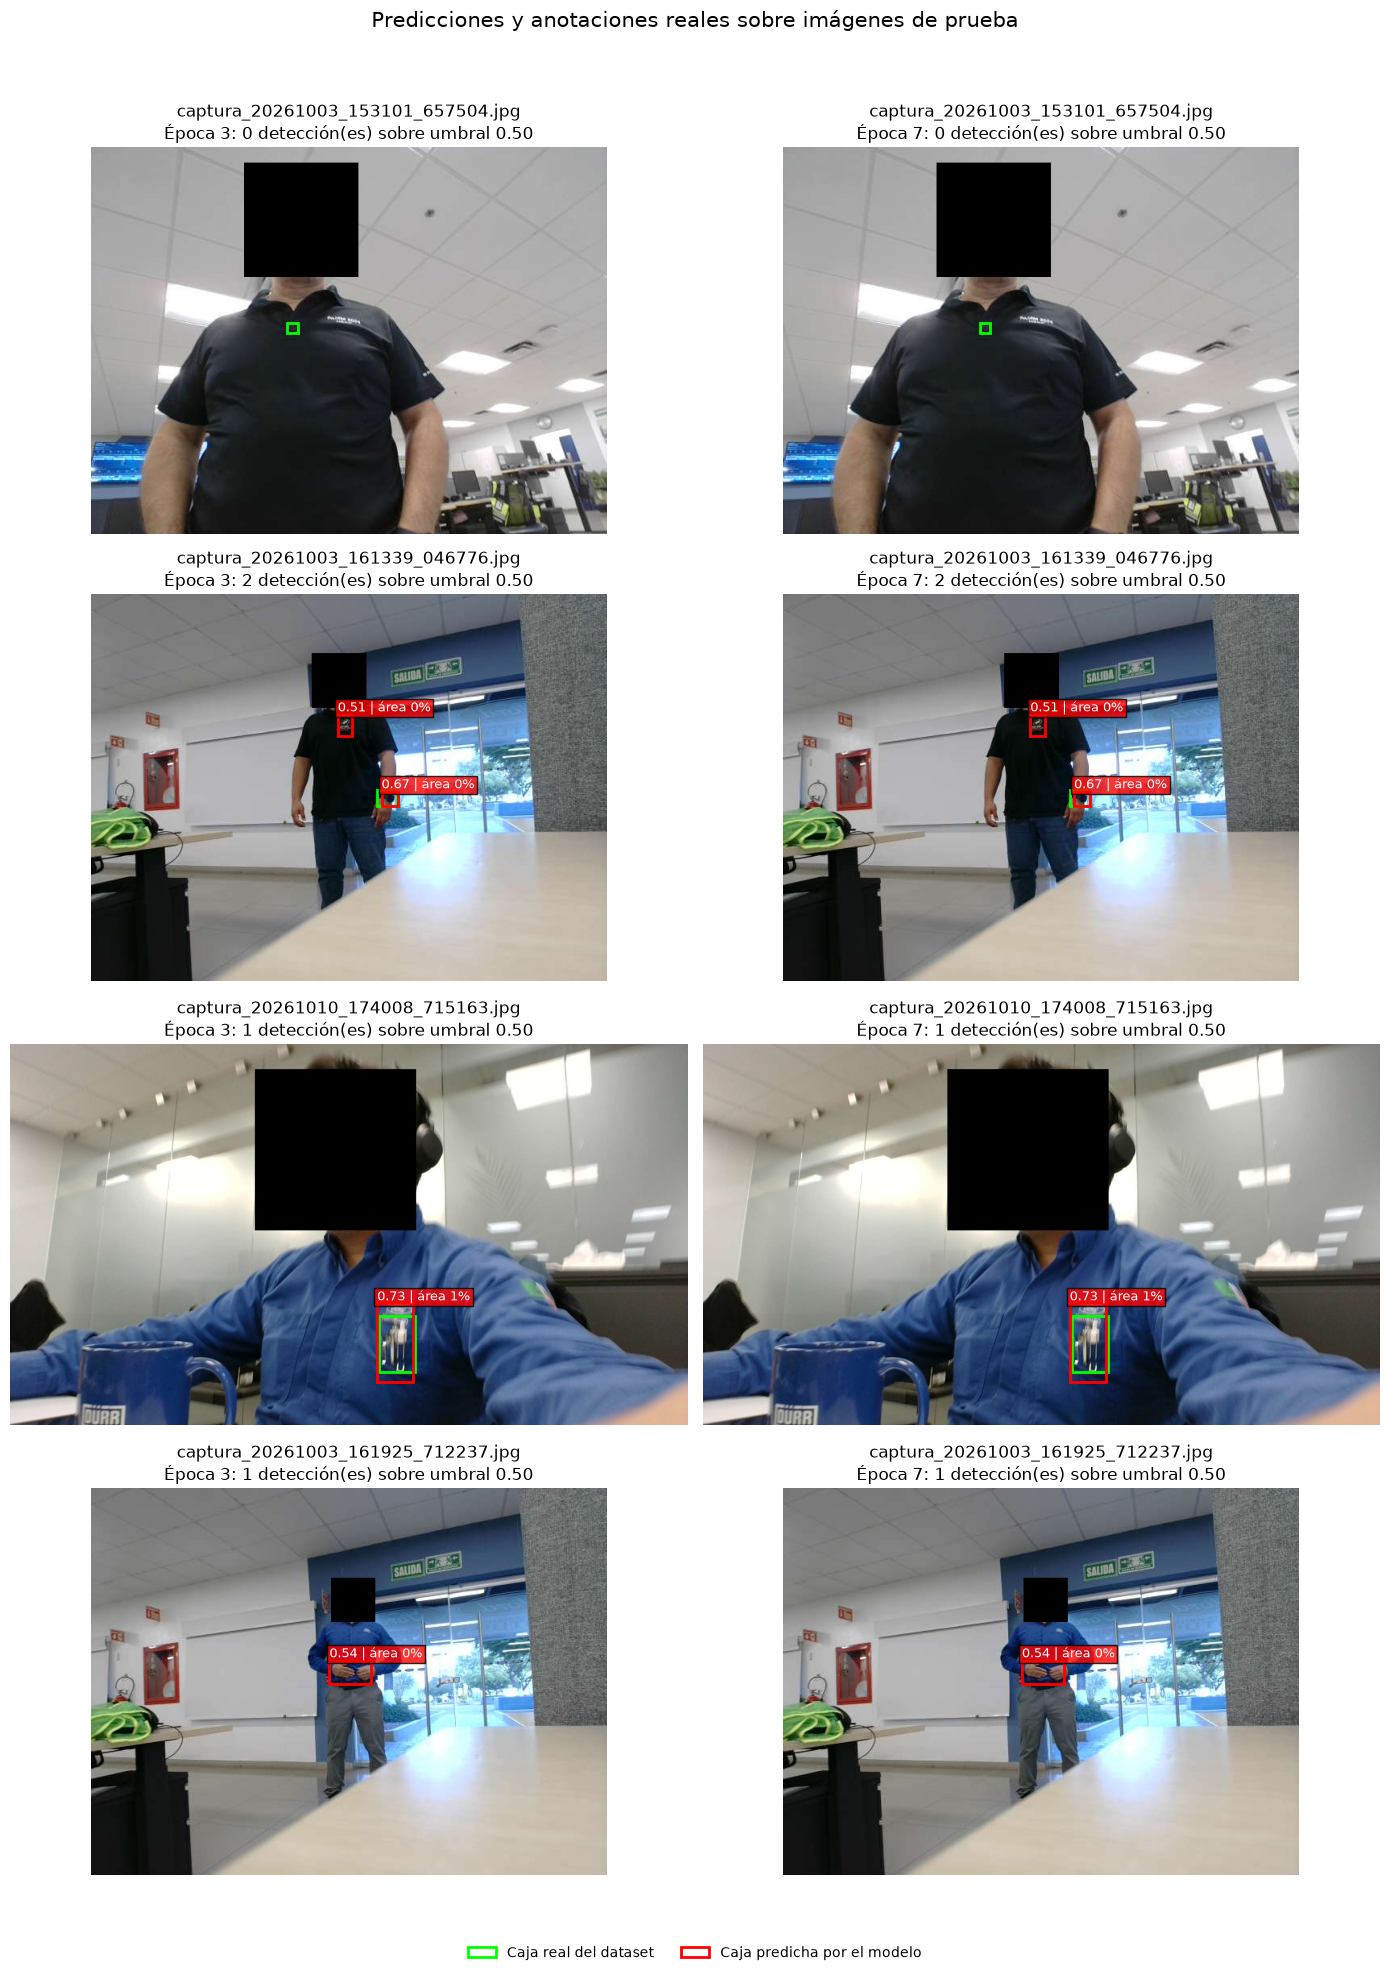

In [44]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
from PIL import Image
from matplotlib.patches import Patch, Rectangle
from torchvision import transforms
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


# Ingresa los checkpoints disponibles.
# Si no tienes uno de ellos, deja su respuesta vacía.
checkpoint_paths = {
    #"Época 3": input("Checkpoint de época 3 (o Enter para omitir): ").strip(),
    #"Época 7": input("Checkpoint de época 7 (o Enter para omitir): ").strip(),
    "Época 3":"../Models/best_fit",
    "Época 7": "../Models/min_val",
}
checkpoint_paths = {
    name: path for name, path in checkpoint_paths.items() if path
}

if not checkpoint_paths:
    raise ValueError("Ingresa al menos un checkpoint disponible.")

# Usa el umbral que hayas seleccionado con el set de validación.
SCORE_THRESHOLD = 0.50
N_IMAGES = 4
RANDOM_STATE = 42

to_tensor = transforms.ToTensor()


def load_detector(checkpoint_path):
    """Reconstruye el detector y carga sus pesos guardados."""
    try:
        checkpoint = torch.load(
            checkpoint_path,
            map_location=device,
            weights_only=True
        )
    except TypeError:
        # Compatibilidad con versiones anteriores de PyTorch.
        checkpoint = torch.load(checkpoint_path, map_location=device)

    if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
        state_dict = checkpoint["model_state_dict"]
    elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
        state_dict = checkpoint["state_dict"]
    else:
        # También admite un state_dict guardado directamente.
        state_dict = checkpoint

    model = fasterrcnn_resnet50_fpn(
        weights=None,
        weights_backbone=None
    )

    # Una clase de objeto más la clase de fondo.
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 2)

    model.load_state_dict(state_dict)
    model.to(device)
    model.eval()
    return model


models = {
    name: load_detector(checkpoint_path)
    for name, checkpoint_path in checkpoint_paths.items()
}


# Normaliza los nombres para emparejar las anotaciones con las imágenes.
ann = annotations.copy()
ann[IMAGE_COL] = ann[IMAGE_COL].astype(str).map(
    lambda name: Path(name).name
)

ann_by_image = {
    name: group
    for name, group in ann.groupby(IMAGE_COL)
}

test_names = (
    test_df[IMAGE_COL]
    .astype(str)
    .map(lambda name: Path(name).name)
    .drop_duplicates()
)

sample_names = test_names.sample(
    n=min(N_IMAGES, len(test_names)),
    random_state=RANDOM_STATE
).tolist()

if not sample_names:
    raise ValueError("No hay imágenes disponibles en test_df.")


def draw_ground_truth(ax, image_name):
    """Dibuja las cajas reales anotadas en verde."""
    boxes = ann_by_image.get(image_name)

    if boxes is None:
        return

    for _, row in boxes.iterrows():
        x = float(row["x"])
        y = float(row["y"])
        w = float(row["w"])
        h = float(row["h"])

        ax.add_patch(Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor="lime",
            linewidth=2
        ))


def draw_predictions(ax, prediction):
    """Dibuja las cajas predichas en rojo e incluye su confianza."""
    keep = prediction["scores"].detach().cpu() >= SCORE_THRESHOLD
    boxes = prediction["boxes"].detach().cpu()[keep]
    scores = prediction["scores"].detach().cpu()[keep]

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box.tolist()

        ax.add_patch(Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        ))

        ax.text(
            x1,
            max(0, y1 - 4),
            f"{score:.2f}",
            color="white",
            fontsize=9,
            bbox={"facecolor": "red", "alpha": 0.8, "pad": 2}
        )

    return len(boxes)


# Una fila por imagen; una columna por checkpoint.
fig, axes = plt.subplots(
    len(sample_names),
    len(models),
    figsize=(7 * len(models), 5 * len(sample_names)),
    squeeze=False
)

for row_idx, image_name in enumerate(sample_names):
    image_path = IMAGE_DIR / image_name

    with Image.open(image_path) as pil_image:
        image = pil_image.convert("RGB")
        image_tensor = to_tensor(image).to(device)

    for col_idx, (model_name, model) in enumerate(models.items()):
        ax = axes[row_idx, col_idx]
        ax.imshow(image)

        # La anotación real se dibuja en todos los paneles para comparar.
        draw_ground_truth(ax, image_name)

        with torch.no_grad():
            prediction = model([image_tensor])[0]

        #n_detections = draw_predictions(ax, prediction)
        n_detections = draw_filtered_predictions(
            ax,
            prediction,
            image.width,
            image.height
            )

        ax.set_title(
            f"{Path(image_name).name}\n"
            f"{model_name}: {n_detections} detección(es) "
            f"sobre umbral {SCORE_THRESHOLD:.2f}"
        )
        ax.axis("off")


legend_handles = [
    Patch(facecolor="none", edgecolor="lime", linewidth=2,
          label="Caja real del dataset"),
    Patch(facecolor="none", edgecolor="red", linewidth=2,
          label="Caja predicha por el modelo"),
]

fig.legend(
    handles=legend_handles,
    loc="lower center",
    ncol=2,
    frameon=False
)

fig.suptitle(
    "Predicciones y anotaciones reales sobre imágenes de prueba",
    fontsize=15
)
plt.tight_layout(rect=[0, 0.04, 1, 0.96])
plt.show()


# Test en video
## Cargar modelo pre-entrenado

In [45]:
from pathlib import Path

import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#checkpoint_file = input("Escribe la ubicación del checkpoint .pth: ").strip()
checkpoint_file = "../Models/best_fit"

try:
    checkpoint = torch.load(
        checkpoint_file,
        map_location=device,
        weights_only=True
    )
except TypeError:
    # Compatibilidad con versiones anteriores de PyTorch.
    checkpoint = torch.load(checkpoint_file, map_location=device)

# Acepta el checkpoint con metadatos o un state_dict guardado directamente.
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    state_dict = checkpoint["model_state_dict"]
elif isinstance(checkpoint, dict) and "state_dict" in checkpoint:
    state_dict = checkpoint["state_dict"]
else:
    state_dict = checkpoint

# Reconstruye la misma arquitectura: Faster R-CNN, accesorio + fondo.
model = fasterrcnn_resnet50_fpn(
    weights=None,
    weights_backbone=None
)

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 2)

model.load_state_dict(state_dict)
model.to(device)
model.eval()

print("Modelo cargado en:", device)


Modelo cargado en: cpu


## Prueba para abrir video

In [46]:
import cv2
import numpy as np

CAMERA_INDEX = 0          # Prueba 1 si la cámara principal no es la correcta.
SCORE_THRESHOLD = 0.50    # Usa el umbral que seleccionaste en validación.
MAX_AREA_FRACTION = 0.35  # Usa tu filtro elegido; pon None para desactivarlo.

cap = cv2.VideoCapture(CAMERA_INDEX)

if not cap.isOpened():
    raise RuntimeError(
        "No se pudo abrir la webcam. Revisa CAMERA_INDEX y los permisos de cámara."
    )

frame_number = 0

try:
    while True:
        ok, frame_bgr = cap.read()
        if not ok:
            print("No se pudo leer un fotograma de la webcam.")
            break

        frame_number += 1
        height, width = frame_bgr.shape[:2]

        # OpenCV entrega BGR; el modelo recibe un tensor RGB con valores [0, 1].
        frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
        image_tensor = (
            torch.from_numpy(frame_rgb)
            .permute(2, 0, 1)
            .float()
            .div(255.0)
            .to(device)
        )

        with torch.no_grad():
            prediction = model([image_tensor])[0]

        boxes = prediction["boxes"].detach().cpu().numpy()
        scores = prediction["scores"].detach().cpu().numpy()
        labels = prediction["labels"].detach().cpu().numpy()

        # Se llena con las detecciones conservadas de este fotograma,
        # en formato [x, y, w, h].
        detections_frame = []

        for box, score, label in zip(boxes, scores, labels):
            if score < SCORE_THRESHOLD or label != 1:
                continue

            x1, y1, x2, y2 = box
            x1 = int(np.clip(round(x1), 0, width - 1))
            y1 = int(np.clip(round(y1), 0, height - 1))
            x2 = int(np.clip(round(x2), 0, width - 1))
            y2 = int(np.clip(round(y2), 0, height - 1))

            box_width = x2 - x1
            box_height = y2 - y1
            if box_width <= 0 or box_height <= 0:
                continue

            area_fraction = (box_width * box_height) / (width * height)

            # Filtro opcional para omitir cajas demasiado grandes.
            if (
                MAX_AREA_FRACTION is not None
                and area_fraction > MAX_AREA_FRACTION
            ):
                continue

            detections_frame.append({
                "x": x1,
                "y": y1,
                "w": box_width,
                "h": box_height,
                "confianza": float(score),
            })

            cv2.rectangle(
                frame_bgr,
                (x1, y1),
                (x2, y2),
                (0, 255, 0),
                2
            )

            texto = f"accesorio {score:.2f}"
            cv2.putText(
                frame_bgr,
                texto,
                (x1, max(22, y1 - 8)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.6,
                (0, 255, 0),
                2
            )

        cv2.putText(
            frame_bgr,
            "Presiona q para salir",
            (10, 28),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7,
            (255, 255, 255),
            2
        )

        cv2.imshow("Detector en webcam", frame_bgr)

        # detections_frame contiene las cajas [x, y, w, h]
        # del fotograma actual, por si quieres inspeccionarlas:
        # print(frame_number, detections_frame)

        key = cv2.waitKey(1) & 0xFF
        if key == ord("q") or key == 27:
            break

finally:
    cap.release()
    cv2.destroyAllWindows()
